<div style="text-align: center; padding-top: 12%;">

# Practical Machine Learning: From Data to Model Selection and Evaluation

## DATA 301 @ WM

<figure class="no-fragment">
<center>
<a href="https://github.com/yanhai-xiong/DATA301-AML/blob/main/Module%203%20-%20Supervised%20Learning%20-%20Regression%20and%20Classification%20Problems/Section%204.1%20-%20Model_Selection_and_Cross_Validations.ipynb" target="_blank">
    <img class="no-fragment"
         src="https://brand.github.com/_next/static/media/logo-03.cc5e5332.png"
         width="80px"/>
</a>
</center>
</figure>
</div>

> How do we know whether our model will work on unseen data, and how do we choose among models? How to build a reliable ML solution?

## <font color='blue' size=5pt>1. From Learning Algorithms to an ML Workflow</font>

So far, we have learned several fundamental components and algorithms for **supervised machine learning**:
- **Optimization:** Gradient Descent (GD) and its variants
- **Regularization:** controlling model complexity and reducing overfitting
- **Regression:** Linear Regression and its extensions
- **Classification:** Logistic Regression, K-Nearest Neighbors (KNN), Decision Trees, and Random Forests
- **Margin-based learning:** Support Vector Machines (SVM) and Support Vector Regression (SVR)

Knowing how these algorithms work is only part of building a successful machine learning system.
In practice, we need to answer a broader set of questions:

> **Given a new dataset and prediction problem, how do we build, evaluate, and select an appropriate machine learning model?**

### Typical **Machine Learning Workflow**

1. **Prepare the data**   Clean the data, handle missing values, encode categorical variables, scale features when necessary, and construct useful features.
2. **Control model complexity**   Understand underfitting and overfitting, and use techniques such as **regularization** to improve generalization.
3. **Evaluate and select models**   Choose appropriate evaluation metrics, split the data properly, use **cross-validation**, and tune model hyperparameters.
4. **Compare candidate models**   Compare different algorithms and configurations based on both predictive performance and practical considerations.
5. **Evaluate the final model**   After model selection is complete, evaluate the selected model on an **unseen test set**.

$$
\boxed{\text{Raw Data}}
\rightarrow
\boxed{\text{Data Preparation}}
\rightarrow
\boxed{\text{Model Training}}
\rightarrow
\boxed{\text{Validation \& Tuning}}
\rightarrow
\boxed{\text{Model Selection}}
\rightarrow
\boxed{\text{Final Evaluation}}
$$

The goal of this section is therefore not to introduce another learning algorithm, but to learn how to use the algorithms we already know to build a reliable machine learning solution.

## <font color='blue' size=5pt>2. Data Preparation</font>

**Goal:** Transform raw data into a form suitable for machine learning while preserving useful information.

| Step | What do we do? | Examples |
|---|---|---|
| **Data Cleaning** | Fix or remove problematic observations | duplicates, incorrect values, inconsistent formats |
| **Missing Values** | Remove or impute missing observations | mean/median, most frequent value |
| **Categorical Encoding** | Convert categorical features to numerical representations | one-hot encoding, ordinal encoding |
| **Feature Scaling** | Put numerical features on comparable scales | standardization, normalization |
| **Feature Engineering** | Create or transform features using domain knowledge | interactions, polynomial features, log transforms |

### <font color='blue'>Does Every Model Need the Same Preparation?</font>

- **Scaling is important:** KNN, SVM/SVR, regularized linear/logistic regression
- **Scaling is usually unnecessary:** Decision Trees, Random Forests
- **Encoding categorical variables:** depends on the model and implementation
- **Feature engineering:** can improve performance, but may also increase model complexity

### <font color='red'>Important Principle</font>

> Any preprocessing step that **learns information from the data** should be fitted using the **training data only** and then applied to validation/test data.

For example, the mean and standard deviation used for standardization should **not** be computed using the test data.

$$
\boxed{\text{Fit preprocessing on training data}}
\quad\longrightarrow\quad
\boxed{\text{Apply to validation/test data}}
$$

## <font color='blue' size=5pt>3. Model Evaluation & Selection</font>

Training a model means finding its **parameters** from data.  

But in practice, we must also decide:
- **How well does the model generalize to unseen data?**
- **Which evaluation metric should we use?**
- **Which hyperparameters should we choose?**
- **Which model should we finally use?**

### <font color='blue' size=5pt>Train, Validation, and Test Sets</font>

Why not simply train and evaluate a model using the same data?

> A model can perform very well on its **training data** but poorly on **unseen data**.

We therefore separate the roles of our data:

| Dataset | Purpose |
|---|---|
| **Training set** | Learn model **parameters** (e.g., ) |
| **Validation set** | Select models and **hyperparameters** (e.g., ) |
| **Test set** | Estimate final performance on **unseen data** |

> The **test set should not be used to make modeling decisions**.

### <font color='blue' size=5pt>Examples: Parameters vs. Hyperparameters</font>

| Model | Parameters (learned) | Hyperparameters (chosen) |
|---|---|---|
| **Linear Regression** | coefficients $\beta_0,\beta_1,\ldots,\beta_p$ | regularization strength $\lambda$ (Ridge/Lasso) |
| **Logistic Regression** | coefficients $\beta_0,\beta_1,\ldots,\beta_p$ | $C$, penalty (L1/L2) |
| **KNN** | *No fitted coefficients*; stores training examples | number of neighbors $k$, distance metric |
| **Decision Tree** | selected features, split points, leaf predictions | `max_depth`, `min_samples_split`, criterion |
| **Random Forest** | fitted trees and their splits/leaf predictions | `n_estimators`, `max_depth`, `max_features` |
| **SVM / SVR** | support vectors, coefficients, intercept $b$ | $C$, kernel, $\gamma$ (for RBF kernel) |

> $$
\boxed{\text{Dataset}}
\rightarrow
\begin{cases}
\text{Training Set} & \rightarrow \text{Fit to find parameters}\\
\text{Validation Set} & \rightarrow \text{Tune/Select hyperparameters}\\
\text{Test Set} & \rightarrow \text{Final Evaluation}
\end{cases}
$$

### <font color='blue' size=5pt>Evaluation Metrics: What Does "Best" Mean?</font>

Before comparing models, we need to decide **how performance will be measured**.

| Problem | Metric | Main Idea | When Useful |
|---|---|---|---|
| **Regression** | **MSE / RMSE** | Penalizes large errors more strongly | Large errors are particularly costly |
| | **MAE** | Average absolute prediction error | Want an interpretable error; more robust to outliers |
| | **$R^2$** | Fraction of variation explained | Describing overall goodness of fit |
| **Classification** | **Accuracy** | Fraction correctly classified | Classes are reasonably balanced and errors have similar costs |
| | **Precision** | How reliable are positive predictions? | **False positives are costly** |
| | **Recall** | How many actual positives are detected? | **False negatives are costly** |
| | **F1-score** | Balance of precision and recall | Imbalanced classes; both FP and FN matter |
| | **ROC-AUC** | Ability to rank positives above negatives across thresholds | Comparing classifiers independent of one threshold |

#### <font color='blue'>Practical Guidelines</font>

- 🏠 **House-price prediction:** use **MAE** for an interpretable typical error; use **RMSE** if large prediction errors should be penalized more heavily.
- 💳 **Fraud detection:** often prioritize **Recall** — missing a fraudulent transaction (FN) can be costly.
- 📧 **Spam detection:** **Precision** may be important — incorrectly sending legitimate email to spam (FP) is undesirable.
- 🩺 **Disease screening:** often prioritize **Recall / Sensitivity** — missing a sick patient (FN) can have serious consequences.
- 🔔 **Alert systems:** often prioritize **Precision** when too many false alarms cause users to ignore alerts.
- ⚖️ **Balanced classification with similar error costs:** **Accuracy** can be a simple and useful metric.
- ⚠️ **Highly imbalanced classification:** do **not rely on accuracy alone**; consider Precision, Recall, F1, and other appropriate metrics.
- 🎚️ **When the classification threshold is not fixed:** use metrics such as **ROC-AUC** to compare ranking ability across thresholds.

> **There is no universally "best" metric — choose the metric based on the goal and the costs of different types of errors.**

### <font color='blue' size=5pt>Why Cross-Validation?</font>

A single train/validation split can be **unstable**:
- Performance may depend on which observations happen to be in the validation set.
- A small validation set provides a noisy estimate of generalization.
- A different random split may lead us to select a different model.

<font color='green'>Idea: Reuse the Training Data More Effectively</font>
- Instead of using only one validation set, evaluate the model on **multiple train/validation splits**.
- The most common approach is **$k$-fold cross-validation**.

#### <font color='blue' size=5pt>$k$-Fold Cross-Validation</font>

1. For a given **set of hyperparameters.**
2. Divide the **training data** into $k$ approximately equal folds. For each fold:
    - Use the other $k-1$ folds to **fit the model parameters**.
    - Use the remaining fold to **evaluate** the model and obtain a validation score.
    - Repeat until every fold has served as the validation fold.
3. **Compute the average CV score** for this hyperparameter configuration:
$
\text{CV Score}=
\frac{1}{k}
\sum_{j=1}^{k}
\text{Validation Score}_j
$

---
- **Common choices:** $k=5$ or $k=10$.
- For classification, **Stratified $k$-Fold** helps preserve class proportions in each fold.

### <font color='blue'>The Complete Flow</font>
👉Initial data split:
$$
\boxed{\text{Full Dataset}}
\longrightarrow
\begin{cases}
\boxed{\text{Training Data}}\\[4pt]
\boxed{\text{Test Data}}
\end{cases}
$$

👉$k$-Fold CV:
$$
\boxed{\text{Training Data}}
\longrightarrow
\boxed{\text{Candidate Hyperparameters}}
\longrightarrow
\boxed{k\text{-Fold CV}}
\longrightarrow
\boxed{\text{CV Scores}}
\longrightarrow
\boxed{\text{Best Hyperparameters}}
$$
- Two common hyperparameter search strategies:
    - **Grid Search:** systematically evaluate specified combinations.
    - **Random Search:** randomly sample combinations from specified ranges/distributions.

👉During each CV fold:
$$
\boxed{k-1\text{ Training Folds}}
\xrightarrow{\text{Fit}}
\boxed{\text{Model Parameters}}
\xrightarrow{\text{Evaluate on Validation Fold}}
\boxed{\text{Validation Score}}
$$

👉After hyperparameter selection:
$$
\boxed{\text{Best Hyperparameters}}
+
\boxed{\text{Full Training Data}}
\xrightarrow{\text{Fit}}
\boxed{\text{Final Parameters}}
\rightarrow
\boxed{\text{Final Model}}
\xrightarrow{\text{Test Once}}
\boxed{\text{Final Performance}}
$$

## <font color='blue' size=5pt>4. Revisit: Regularization & Model Complexity</font>

**Regularization** controls model complexity to reduce **overfitting** and improve generalization.

A common form is:

$$
\boxed{\text{Objective}=\text{Training Loss}+\text{Regularization Penalty}}
$$

| Model \/ Method | Complexity Control | Effect of Increasing Regularization \/ Control |
|---|---|---|
| **Ridge (L2)** | $\lambda\sum_j w_j^2$ | $\lambda\uparrow$ → smaller coefficients → simpler model |
| **Lasso (L1)** | $\lambda \sum_j \|w_j\|$ | $\lambda\uparrow$ → more coefficients become $0$ |
| **Elastic Net (L1 + L2)** | $\lambda[\alpha\sum_j\|w_j\|+(1-\alpha)\sum_jw_j^2]$ | $\lambda\uparrow$ → stronger shrinkage; can produce sparse solutions |
| **Logistic Regression** | L1/L2/Elastic Net; often controlled by $C=\frac{1}{\lambda}$ | $C\uparrow$ → weaker regularization → more complex model |
| **SVM / SVR** | $\frac{1}{2}\|w\|^2+C\cdot\text{Loss of violations}$ | $C\uparrow$ → prioritize training fit → more complex model |
| **KNN** | Number of neighbors $k$ | $k\uparrow$ → smoother boundary → simpler model |
| **Decision Tree** | `max_depth`, `min_samples_leaf` | deeper tree → more complex model |
| **Random Forest** | Tree depth, `min_samples_leaf`, `max_features`, etc. | More flexible trees → greater complexity |

### <font color='blue'>Key Connections</font>

- **L1** encourages **sparsity** → some coefficients can become exactly $0$.
- **L2** shrinks coefficients toward $0$ but usually does not make them exactly $0$.
- $\lambda \uparrow$ → **stronger regularization**.
- $C \uparrow$ → **weaker regularization** in common Logistic Regression and SVM formulations.
- $k$, tree depth, etc. are not regularization penalties, but they also **control model complexity**.

$$
\boxed{\text{Too Simple}}
\;\longleftrightarrow\;
\boxed{\text{Appropriate Complexity}}
\;\longleftrightarrow\;
\boxed{\text{Too Complex}}
$$

> Regularization and other complexity controls are **hyperparameters** and can be selected using **cross-validation**.

## <font color='blue'>5. Bias–Variance Tradeoff</font>

<div align="center">
<img src="https://upload.wikimedia.org/wikipedia/commons/9/9f/Bias_and_variance_contributing_to_total_error.svg" width="400">
</div>

A key challenge in model selection is choosing the **right model complexity** to achieve good generalization on unseen data.
- **High bias**: The model makes similar mistakes across different training datasets. It is consistently wrong.
- **High variance**: The model produces substantially different predictions depending on which training dataset it receives. It is unstable.
- **Good generalization**: We want both squared bias and variance to be sufficiently small.

### Practical Approach
For squared-error prediction, the expected test error is:
$$
\underbrace{\mathbb{E}[(Y-\hat f(X))^2]}_{\text{Expected Test MSE}} =
\underbrace{\text{Bias}^2}_{\text{Systematic error}}
+
\underbrace{\text{Variance}}_{\text{Sensitivity to training data}}
+
\underbrace{\sigma^2}_{\text{Irreducible noise}}
$$

**Key takeaway:** Increasing complexity generally reduces bias but increases variance. The goal is to find a balance that minimizes **expected test error**, not simply training error.

**Practical approach:** Use **cross-validation** to select model complexity and regularization strength.

## <font color='blue'>6. Practical Model Selection</font>

**No single model works best for every problem.** Model selection depends on the dataset, prediction task, performance requirements, and practical constraints.

Practical Considerations:
- **Task:** Regression vs. classification; binary vs. multiclass.
- **Dataset:** Number of samples, features, noise, missing values, and class imbalance.
- **Interpretability:** Simple models are generally easier to explain.
- **Computational cost:** Training time, prediction latency, and memory.
- **Preprocessing:** Scaling is important for KNN and SVM; trees/RF generally do not require it.
- **Model complexity:** Tune hyperparameters to balance underfitting and overfitting.

### Comparing Common ML Models

| Model | Strengths | Limitations | When to Consider |
|---|---|---|---|
| **Linear / Logistic Regression** | Fast, interpretable, simple baseline | Limited nonlinear patterns without feature engineering | Linear relationships, interpretability |
| **KNN** | Simple, flexible, nonlinear | Sensitive to scaling and irrelevant features; slow prediction on large datasets | Small datasets, low-dimensional features |
| **Decision Tree** | Interpretable, nonlinear, handles feature interactions | Prone to overfitting; unstable | Explainable decision rules |
| **Random Forest (RF)** | Strong generalization, handles nonlinear relationships | Less interpretable, more computationally expensive | General-purpose tabular data |
| **SVM / SVR** | Effective in high-dimensional spaces; kernels enable nonlinear modeling | Sensitive to scaling and hyperparameters; costly for large datasets | Small/medium datasets, complex boundaries |

### Recommended Workflow

1. **Start simple:** Establish a baseline using linear/logistic regression or a decision tree.
2. **Try alternatives:** Compare KNN, RF, and SVM/SVR as appropriate.
3. **Tune hyperparameters:** Use cross-validation (e.g., $k$, `max_depth`, `n_estimators`, $C$, `gamma`).
4. **Compare validation performance:** Choose metrics appropriate for the task (e.g., RMSE/MAE, F1, ROC-AUC).
5. **Evaluate once on the held-out test set:** Estimate generalization performance.

**Key takeaway:** The best model is not necessarily the most complex or most accurate on training data—it is the one that **generalizes well while meeting practical requirements**.

## <font color='blue'>7. Data Leakage & Pipelines</font>

**Data leakage** can leads to **overly optimistic performance estimates**.
Common examples:
- **Preprocessing leakage:** Scaling, imputing, or selecting features using the entire dataset before cross-validation (especially in CV, make sure to fit the scaler **only on the training folds**).
- **Test-set leakage:** Using test data to tune hyperparameters or select models.
- **Target leakage:** Using features that contain information about the target that would not be available when making predictions.


### <font color='blue'>Pipelines & Hyperparameter Tuning</font>

Scikit-learn provides two useful tools: $
\boxed{\text{Pipeline} + \text{GridSearchCV}
= \text{Leakage-safe CV-based model tuning}}
$ 

**1. `Pipeline`:** Chains preprocessing and model training into one workflow.
$$
\text{Raw Data}
\;\longrightarrow\;
\text{Preprocessing}
\;\longrightarrow\;
\text{Model}
\;\longrightarrow\;
\text{Prediction}
$$
- Ensures preprocessing is fitted on the appropriate training data.
- Applies the same transformations consistently to validation/test data.
- Allows preprocessing and model hyperparameters to be tuned together.

**2. `GridSearchCV`:** Searches over specified hyperparameter combinations using cross-validation.
- Trains and evaluates each combination across CV folds.
- Selects the combination with the best mean CV score.
- Refits the selected pipeline on the full training dataset by default.

### **Recommended workflow:**

1. Split data into **training and held-out test sets**.
2. Define a `Pipeline` with preprocessing and a model.
3. Use `GridSearchCV` on the training set.
4. Evaluate the best pipeline **once on the test set**.

**Important:** A pipeline prevents preprocessing leakage across CV folds when used correctly, but cannot automatically prevent target leakage or misuse of the test set.

## <font color='blue'>8. Putting Everything Together: End-to-End Model Selection</font>

### Complete Machine Learning Workflow

1. **Define the problem and evaluation metric**
   - Regression: MAE, RMSE, $R^2$.
   - Classification: Accuracy, Precision, Recall, F1, ROC-AUC.

2. **Split the data**
   - Separate **training** and **test** sets before data-dependent preprocessing.
   - Keep the test set untouched until final evaluation.

3. **Build candidate pipelines**
   - Choose models (e.g., Linear/Logistic Regression, KNN, RF, SVM).
   - Include preprocessing (scaling, imputation, feature selection) inside each pipeline.

4. **Cross-validation & hyperparameter tuning**
   - Use `GridSearchCV` or `RandomizedSearchCV` on the training set.
   - Compare models and hyperparameters using the same CV strategy and metric.
   - Consider bias–variance tradeoffs and computational cost.

5. **Select and refit the best model**
   - Choose based on CV performance and practical requirements.
   - Refit the selected pipeline on the **entire training set**.
   - `GridSearchCV(refit=True)` does this automatically.

6. **Final test evaluation**
   - Evaluate the selected model **once on the held-out test set**.
   - Report appropriate metrics and analyze prediction errors.
   - Do not tune the model based on test performance.

7. **Deploy and monitor (optional)**
   - Save the complete preprocessing + model pipeline.
   - Monitor performance and data distribution changes over time.

### Key Distinction: CV vs. Test Set

| | Cross-Validation | Held-Out Test Set |
|---|---|---|
| **Purpose** | Model selection & tuning | Final generalization estimate |
| **Data used** | Training data only | Unseen test data |
| **Used repeatedly?** | Yes | Ideally once |
| **Influences model selection?** | Yes | No |

**Final takeaway:** Build a reproducible pipeline, use **cross-validation to select and tune models**, and reserve the **test set for an unbiased final performance estimate**.


# <font color='blue'> Code Applications </font>

---

## Setup

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#import statsmodels.api as sm
from sklearn.model_selection import RepeatedKFold
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import mean_squared_error as mse
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import ElasticNet, Ridge, Lasso
#from yellowbrick.regressor import ResidualsPlot

## Data Import

In [2]:
data_housing = pd.read_csv('https://github.com/yanhai-xiong/DATA301-AML/blob/main/Data%20Sets/housing.csv?raw=true')
data_concrete = pd.read_csv('https://github.com/yanhai-xiong/DATA301-AML/blob/main/Data%20Sets/concrete.csv?raw=true')

## Coefficient Paths on Housing Example

In [3]:
feats = ['crime','residential','industrial','nox','rooms','older','distance','highway','tax','ptratio','lstat']
X = data_housing[feats]
y = data_housing['cmedv'].values

In [4]:
scale = StandardScaler()
Xs = scale.fit_transform(X)

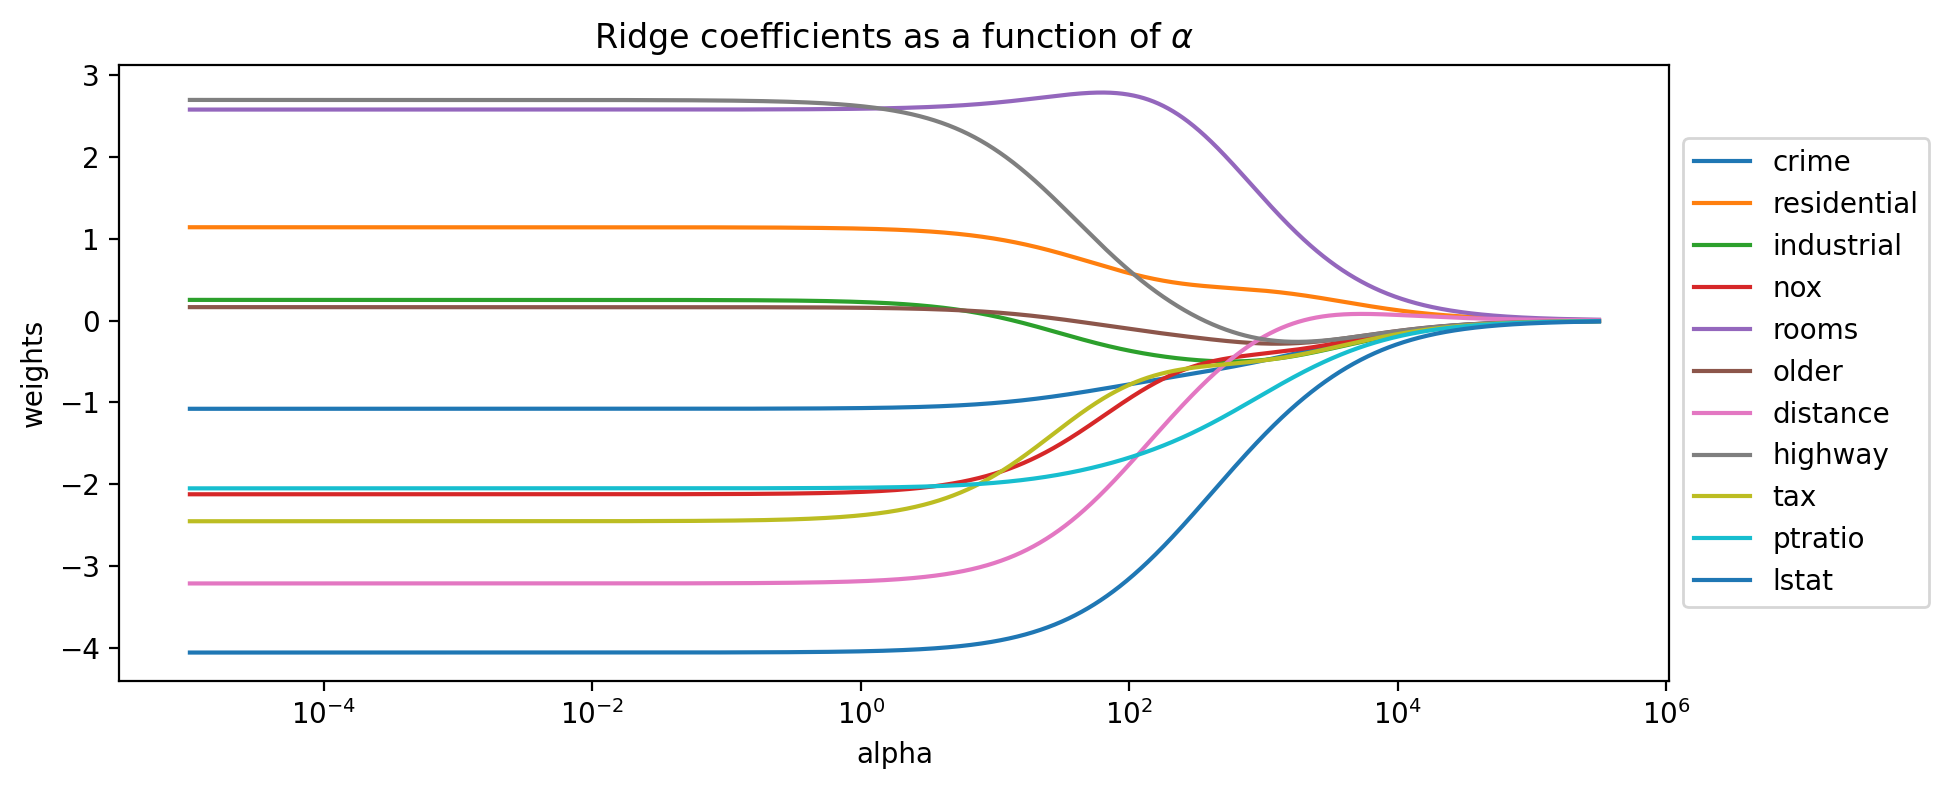

In [7]:
# generate the coefficients for Ridge regression and many values of alpha
n_alphas = 2000
alphas = np.logspace(-5, 5.5, n_alphas)

coefs = []
for a in alphas:
    ridge = Ridge(alpha=a, fit_intercept=False)
    ridge.fit(Xs, y)
    coefs.append(ridge.coef_)

# Display coefficient paths Ridge
plt.figure(figsize=(10, 4))

ax = plt.gca()
ax.plot(alphas, coefs)
ax.set_xscale('log')
plt.xlabel('alpha')
plt.ylabel('weights')
plt.title('Ridge coefficients as a function of $\\alpha$')
plt.axis('tight')
plt.legend(feats, bbox_to_anchor=[1,0.5], loc='center left')
plt.savefig('example_coeff_paths.png',dpi=300,bbox_inches='tight')
plt.show()

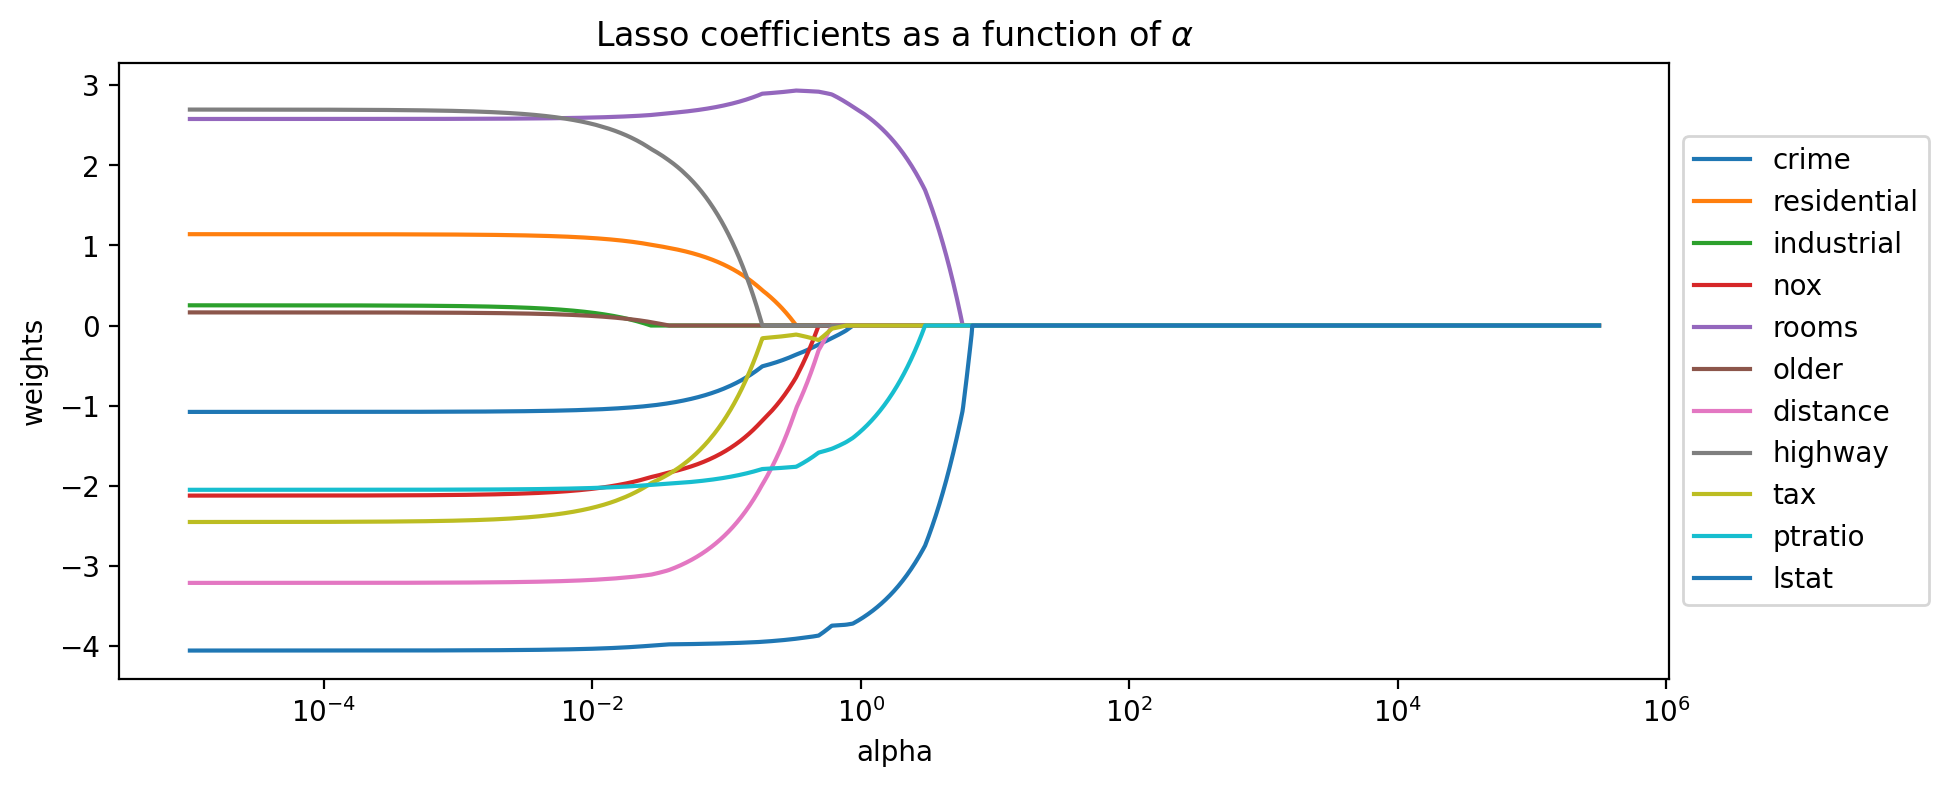

In [8]:
# generate the coefficients for Ridge regression and many values of alpha
n_alphas = 2000
alphas = np.logspace(-5, 5.5, n_alphas)

coefs = []
for a in alphas:
    model = Lasso(alpha=a, fit_intercept=False)
    model.fit(Xs, y)
    coefs.append(model.coef_)

# Display coefficient paths Ridge
plt.figure(figsize=(10, 4))

ax = plt.gca()
ax.plot(alphas, coefs)
ax.set_xscale('log')
plt.xlabel('alpha')
plt.ylabel('weights')
plt.title('Lasso coefficients as a function of $\\alpha$')
plt.axis('tight')
plt.legend(feats, bbox_to_anchor=[1,0.5], loc='center left')
plt.show()

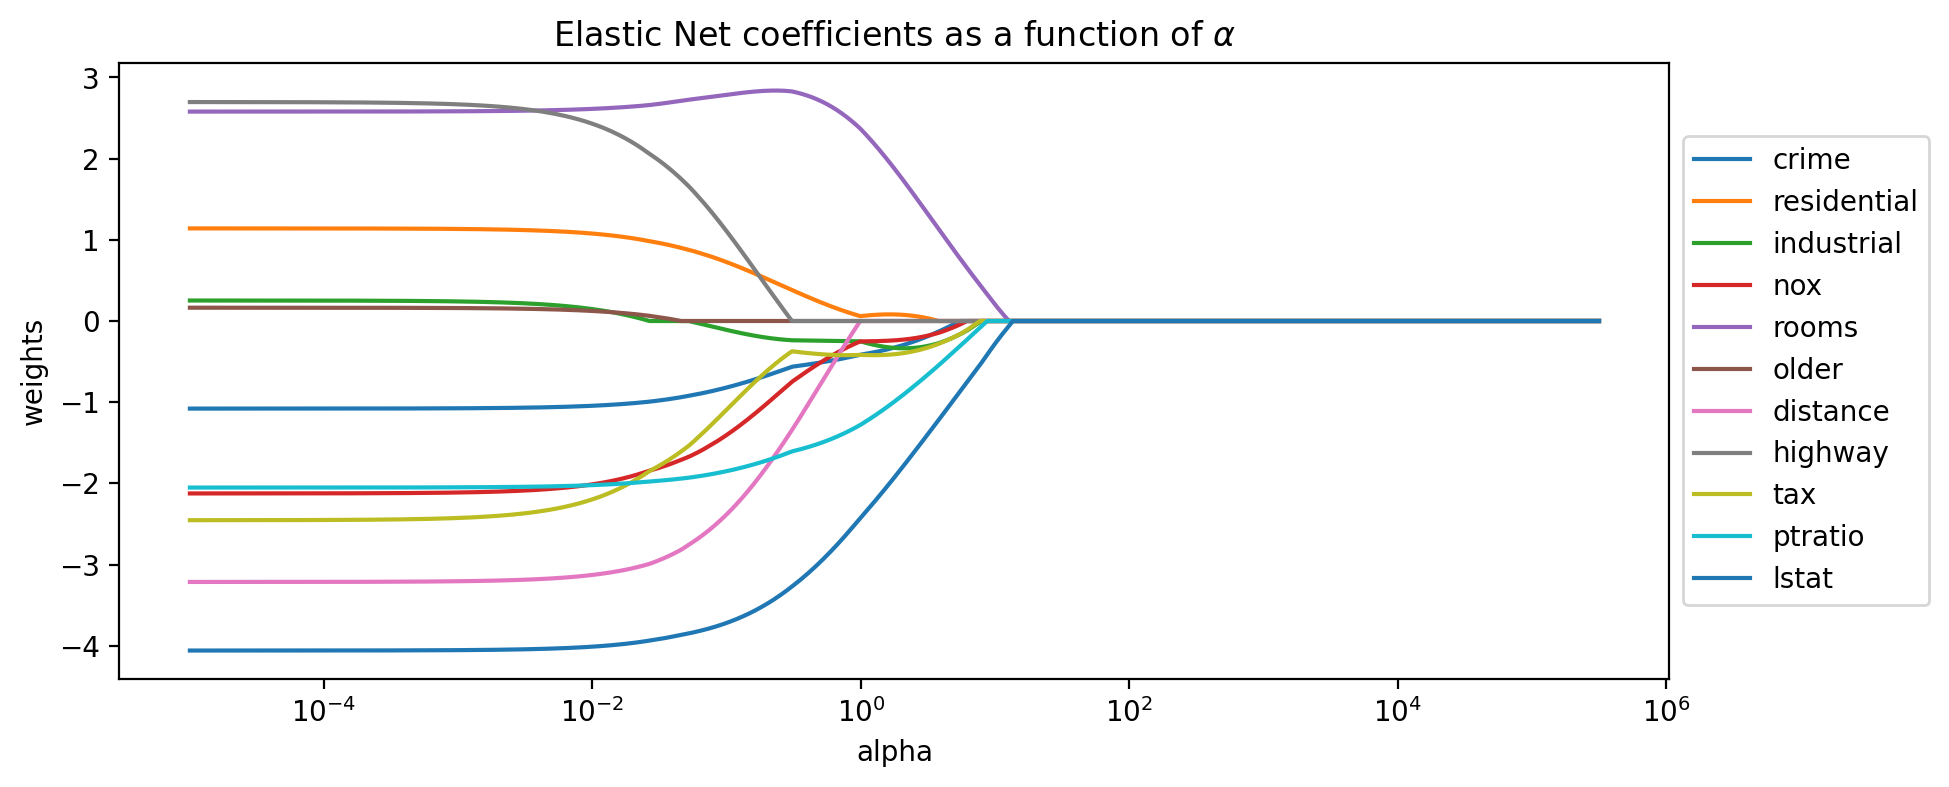

In [9]:
# generate the coefficients for Ridge regression and many values of alpha
n_alphas = 2000
alphas = np.logspace(-5, 5.5, n_alphas)

coefs = []
for a in alphas:
    model = ElasticNet(alpha=a, fit_intercept=False)
    model.fit(Xs, y)
    coefs.append(model.coef_) # generate the coefficients for Ridge regression and many values of alpha

# Display coefficient paths Ridge
plt.figure(figsize=(10, 4))

ax = plt.gca()
ax.plot(alphas, coefs)
ax.set_xscale('log')
plt.xlabel('alpha')
plt.ylabel('weights')
plt.title('Elastic Net coefficients as a function of $\\alpha$')
plt.axis('tight')
plt.legend(feats, bbox_to_anchor=[1,0.5], loc='center left')
plt.show()

## Example for the Distribution of the Residuals

In [3]:
y = data_concrete['strength']
x = data_concrete.drop(columns='strength')

In [20]:
!pip install yellowbrick
%pip install --upgrade yellowbrick


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
from yellowbrick.regressor import ResidualsPlot

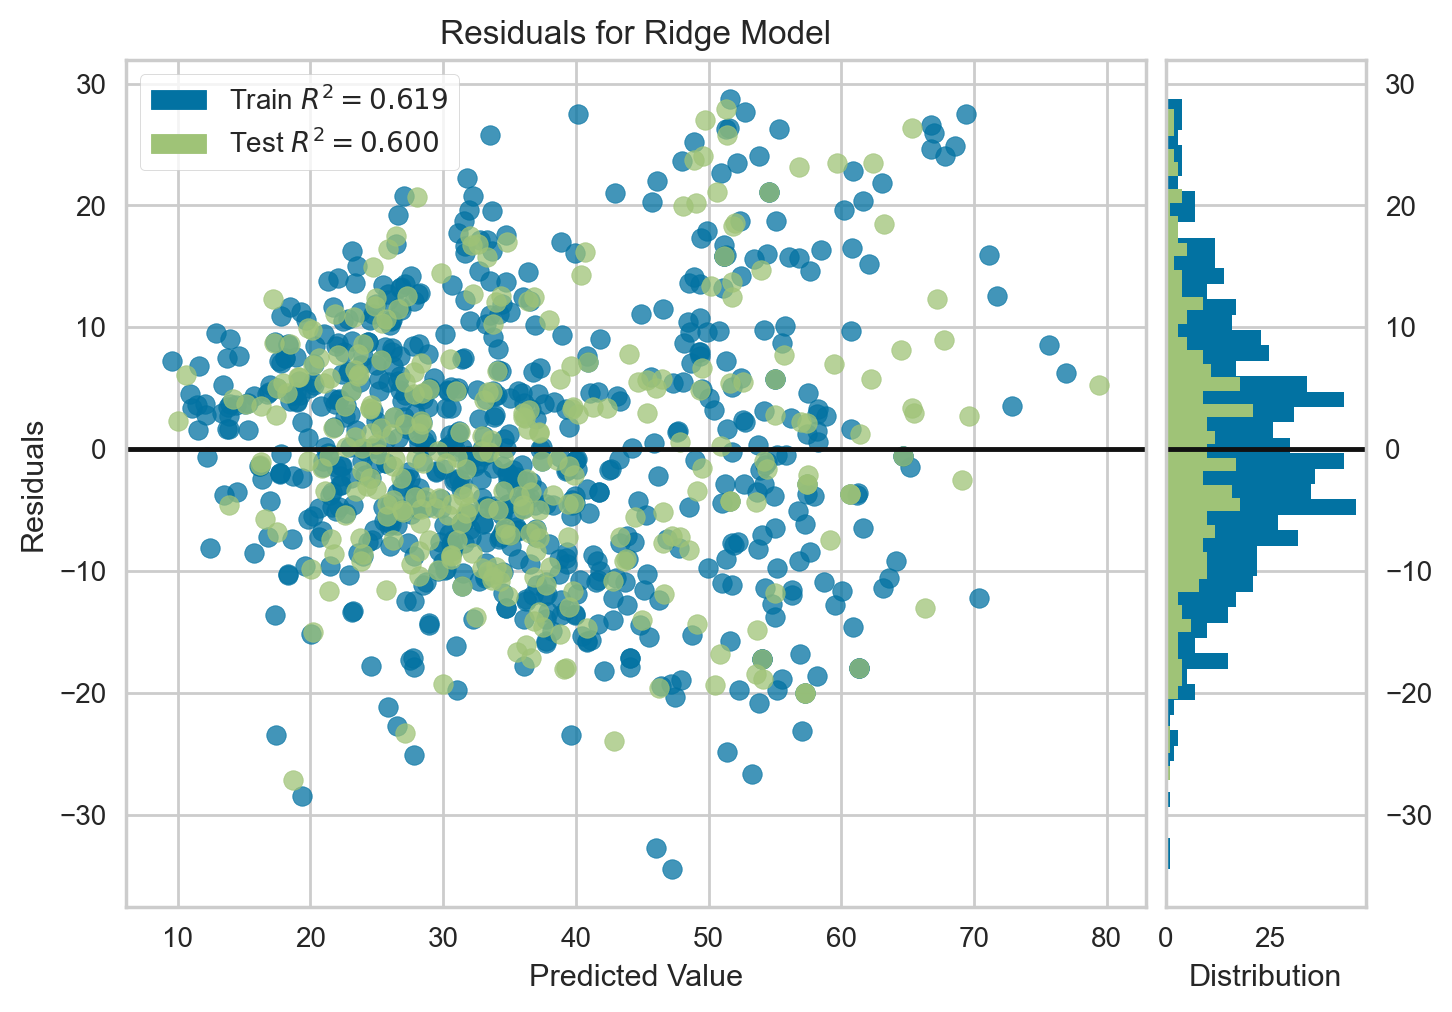

In [10]:
# Create the train and test data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1234)

# Instantiate the linear model and visualizer
# model = ElasticNet(alpha=0.01)
model = Ridge(alpha=10, fit_intercept=True)
visualizer = ResidualsPlot(model , force_model=True)

visualizer.fit(X_train, y_train)  # Fit the training data to the visualizer
visualizer.score(X_test, y_test)  # Evaluate the model on the test data
visualizer.poof()
plt.show()

## Complete Workflow with Concrete Data

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, cross_validate, GridSearchCV, KFold
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score
)

# Features and target
y = data_concrete['strength']
X = data_concrete.drop(columns='strength')

print("Dataset shape:", X.shape)
display(X.head(3))
display(X.describe())

Dataset shape: (1030, 8)


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1234
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 721
Test samples: 309


In [15]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")), # handle missing values (NaN) in a dataset
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=20000))
    ]),

    "ElasticNet": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ]), # Average target value of nearest neighbors

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(
            max_depth=5, random_state=1234
        ))
    ]), # Predict mean target value in a leaf

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100, random_state=1234, n_jobs=-1
        ))
    ]), # Average predictions from trees

    "SVR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf", C=10))
    ])
}

In [16]:
# random_state: Make the shuffle reproducible
cv = KFold(n_splits=5, shuffle=True, random_state=1234)

results = []

for name, pipeline in models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        # scikit-learn's model selection interface follows a convention:
        # Higher scores are always considered better
        scoring={
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        n_jobs=-1 # n_jobs controls the number of parallel workers
        # n_jobs=-1	Use all available CPUs
    )

    results.append({
        "Model": name,
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV RMSE Std": scores["test_RMSE"].std(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

results_df = pd.DataFrame(results).sort_values("CV RMSE")

display(results_df.round(3))

,Model,CV RMSE,CV RMSE Std,CV MAE,CV R2
6,Random Forest,5.851,0.614,4.128,0.878
7,SVR,7.724,0.472,5.578,0.789
5,Decision Tree,8.949,1.153,6.663,0.713
4,KNN,9.446,0.441,7.306,0.685
1,Ridge,10.663,0.644,8.415,0.597
0,Linear Regression,10.666,0.632,8.405,0.596
2,Lasso,10.679,0.708,8.477,0.596
3,ElasticNet,10.784,0.764,8.605,0.588


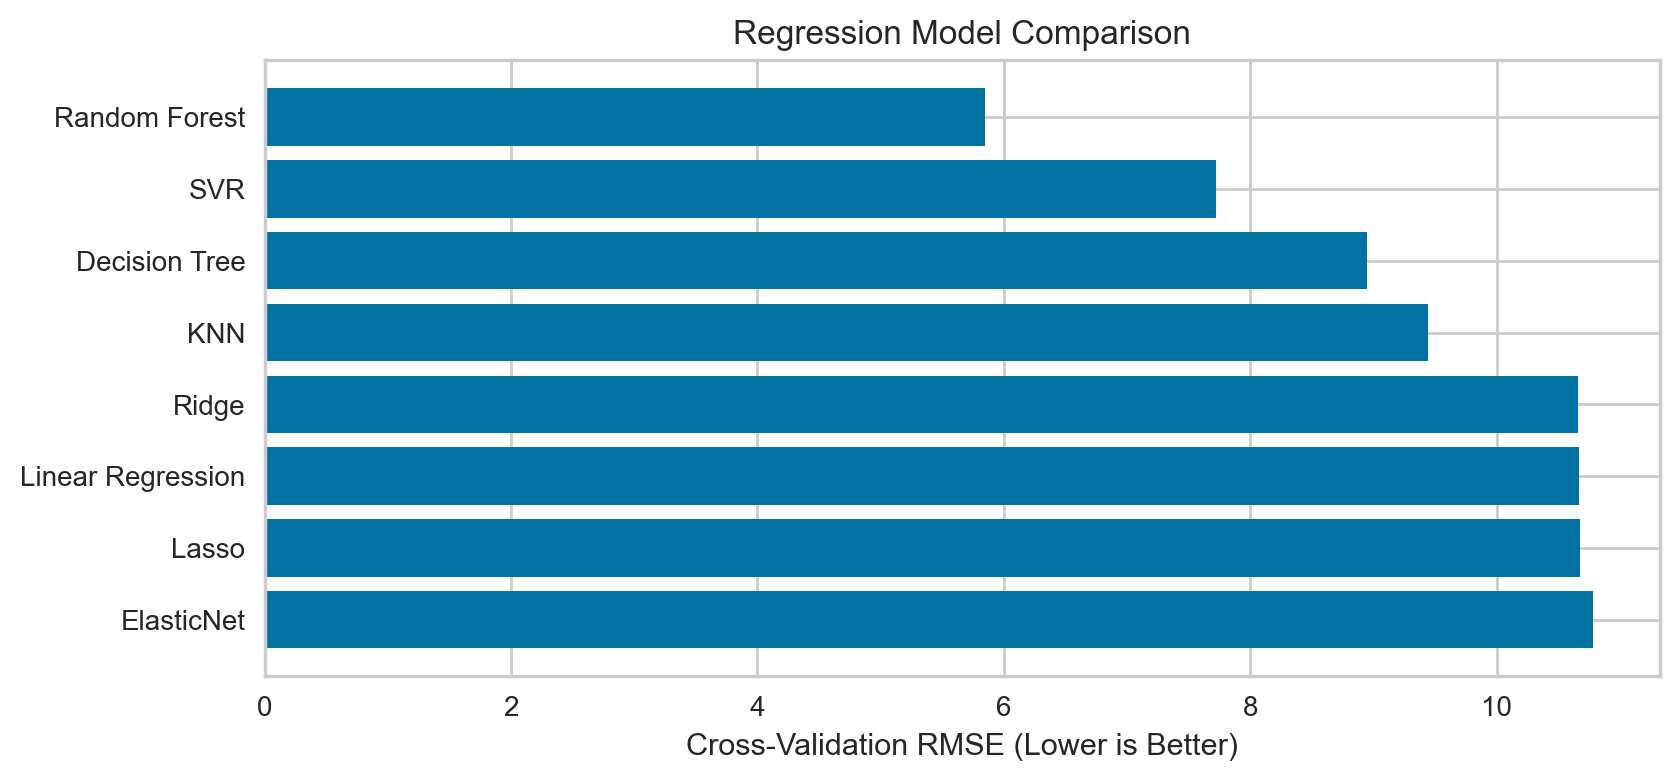

In [17]:
plt.figure(figsize=(9, 4))
plt.barh(results_df["Model"], results_df["CV RMSE"])
plt.xlabel("Cross-Validation RMSE (Lower is Better)")
plt.title("Regression Model Comparison")
plt.gca().invert_yaxis()
plt.show()

In [18]:
search_spaces = {
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 3]
    },

    "SVR": {
        "model__C": [1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1],
        "model__epsilon": [0.1, 0.5]
    }
}

tuned_models = {}

for name, param_grid in search_spaces.items():

    search = GridSearchCV(
        estimator=models[name],
        param_grid=param_grid,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1, 
        refit=True # Automatically train the selected model on all training data
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print("Best CV RMSE:", round(-search.best_score_, 3))


Random Forest
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV RMSE: 5.772

SVR
Best parameters: {'model__C': 100, 'model__epsilon': 0.5, 'model__gamma': 0.1}
Best CV RMSE: 6.683


In [19]:
tuning_results = pd.DataFrame([
    {
        "Model": name,
        "Best CV RMSE": -search.best_score_,
        "Best Parameters": search.best_params_
    }
    for name, search in tuned_models.items()
]).sort_values("Best CV RMSE")

display(tuning_results)

best_name = tuning_results.iloc[0]["Model"]
best_search = tuned_models[best_name]

# Get the fully fitted pipeline, including preprocessing steps 
# and the model with its optimal hyperparameters
final_model = best_search.best_estimator_

print("Selected model:", best_name)

,Model,Best CV RMSE,Best Parameters
0,Random Forest,5.771981,"{'model__max_depth': None, 'model__min_samples..."
1,SVR,6.683145,"{'model__C': 100, 'model__epsilon': 0.5, 'mode..."


Selected model: Random Forest


In [20]:
y_pred = final_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print("Final Test Performance")
print(f"RMSE: {test_rmse:.3f}")
print(f"MAE:  {test_mae:.3f}")
print(f"R²:   {test_r2:.3f}")

Final Test Performance
RMSE: 4.834
MAE:  3.454
R²:   0.910


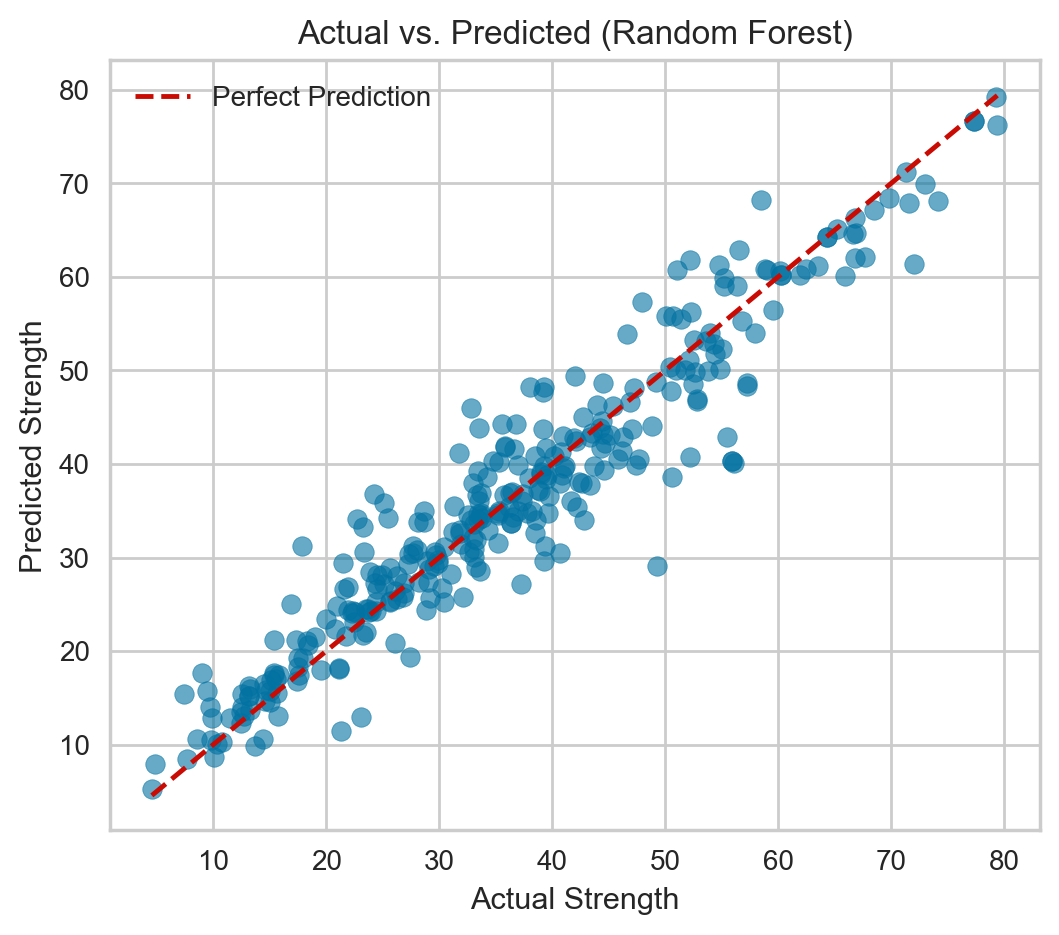

In [21]:
plt.figure(figsize=(6, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, 'r--', label="Perfect Prediction")

plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title(f"Actual vs. Predicted ({best_name})")
plt.legend()
plt.show()

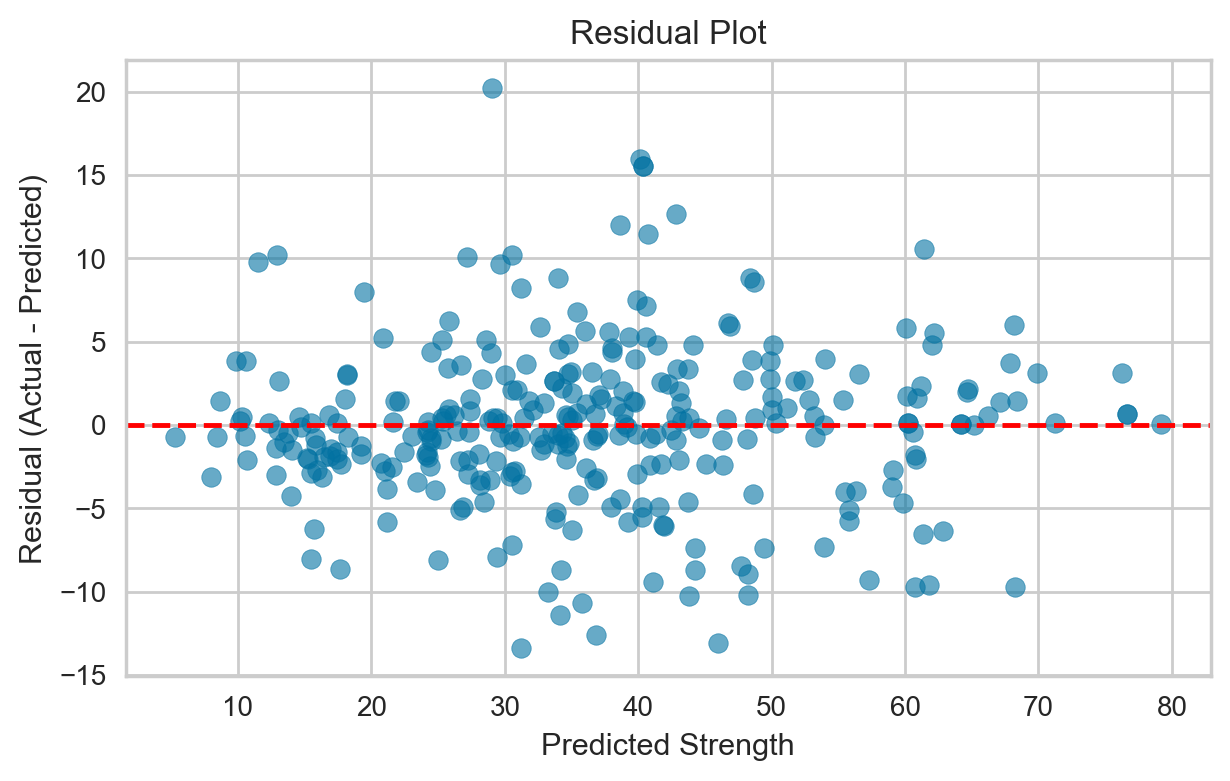

In [22]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Strength")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

# Active Coding
Can you implement the whole workflow on the housing data